In [5]:

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import (
    DecisionBoundaryDisplay,
    permutation_importance,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import (
    DecisionTreeClassifier,
    export_text,
    plot_tree,
)

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA)
print("Model directory:", MODELS)


Project root: C:\Users\Wong Siong Feng\Desktop\UTP-Machine-Learning
Dataset directory: C:\Users\Wong Siong Feng\Desktop\UTP-Machine-Learning\all_datasets
Model directory: C:\Users\Wong Siong Feng\Desktop\UTP-Machine-Learning\models


## PartA—KNN versus Gaussian naive Bayes.

In [6]:

cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

X_c = cancer.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore",
)

y_c = (cancer["diagnosis"] == "M").astype(int)

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c,
    y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c,
)

print("Training shape:", Xc_train.shape)
print("Validation shape:", Xc_valid.shape)
print("\nClass distribution:")
print(y_c.value_counts())


Training shape: (426, 30)
Validation shape: (143, 30)

Class distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


In [7]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

k_values = [1, 3, 5, 7, 11, 21]
cv_scores = {}

for k in k_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        (
            "model",
            KNeighborsClassifier(
                n_neighbors=k,
                weights="distance",
            ),
        ),
    ])

    scores = cross_val_score(
        candidate,
        Xc_train,
        yc_train,
        cv=cv,
        scoring="roc_auc",
    )

    cv_scores[k] = scores.mean()

    print(
        f"k={k:2d} "
        f"cross-validated ROC AUC={scores.mean():.3f}"
    )

best_k = max(cv_scores, key=cv_scores.get)

print("Selected k:", best_k)

k= 1 cross-validated ROC AUC=0.946
k= 3 cross-validated ROC AUC=0.984
k= 5 cross-validated ROC AUC=0.985
k= 7 cross-validated ROC AUC=0.987
k=11 cross-validated ROC AUC=0.988
k=21 cross-validated ROC AUC=0.988
Selected k: 11


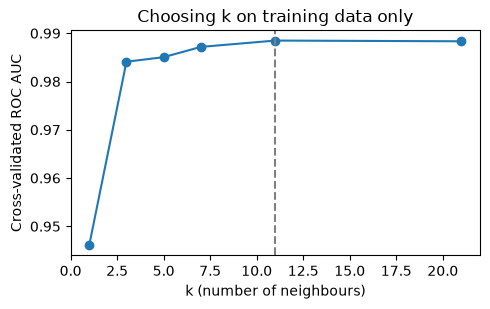

In [8]:
plt.figure(figsize=(5, 3.2))

plt.plot(
    k_values,
    [cv_scores[k] for k in k_values],
    marker="o",
)

plt.axvline(
    best_k,
    linestyle="--",
    color="grey",
)

plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("Choosing k on training data only")

plt.tight_layout()
plt.show()

In [9]:
models = {
    "KNN": Pipeline([
        ("scale", StandardScaler()),
        (
            "model",
            KNeighborsClassifier(
                n_neighbors=best_k,
                weights="distance",
            ),
        ),
    ]),

    "GaussianNB": Pipeline([
        ("scale", StandardScaler()),
        ("model", GaussianNB()),
    ]),
}

for name, model in models.items():
    model.fit(Xc_train, yc_train)

    pred = model.predict(Xc_valid)
    prob_c = model.predict_proba(Xc_valid)[:, 1]

    print(
        f"{name:10s} "
        f"accuracy={accuracy_score(yc_valid, pred):.3f} "
        f"roc_auc={roc_auc_score(yc_valid, prob_c):.3f}"
    )

KNN        accuracy=0.958 roc_auc=0.986
GaussianNB accuracy=0.944 roc_auc=0.992


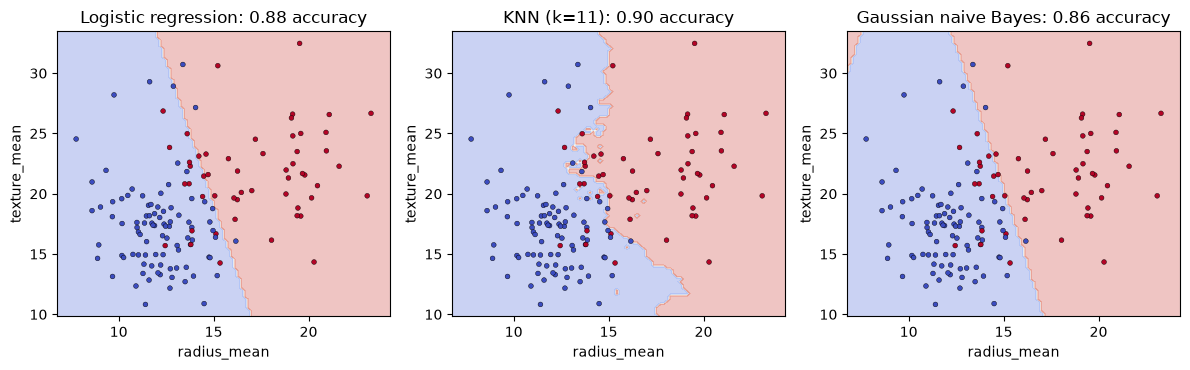

In [10]:
two = ["radius_mean", "texture_mean"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

boundary_models = [
    ("Logistic regression", LogisticRegression(max_iter=2000)),
    (
        f"KNN (k={best_k})",
        KNeighborsClassifier(
            n_neighbors=best_k,
            weights="distance",
        ),
    ),
    ("Gaussian naive Bayes", GaussianNB()),
]

for ax, (name, estimator) in zip(axes, boundary_models):
    small = Pipeline([
        ("scale", StandardScaler()),
        ("model", estimator),
    ])

    small.fit(Xc_train[two], yc_train)

    DecisionBoundaryDisplay.from_estimator(
        small,
        Xc_valid[two],
        ax=ax,
        alpha=0.3,
        response_method="predict",
        cmap="coolwarm",
    )

    ax.scatter(
        Xc_valid[two[0]],
        Xc_valid[two[1]],
        c=yc_valid,
        cmap="coolwarm",
        s=12,
        edgecolor="k",
        linewidth=0.3,
    )

    ax.set_title(
        f"{name}: "
        f"{accuracy_score(yc_valid, small.predict(Xc_valid[two])):.2f} "
        "accuracy"
    )

    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")

plt.tight_layout()
plt.show()

## Part B — Decision trees and overfitting

In [11]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")

features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
]

t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]

X_t = titanic[features]
y_t = titanic["Survived"]

print("Dataset shape:", titanic.shape)
print("\nMissing values:")
print(X_t.isnull().sum())

Dataset shape: (891, 12)

Missing values:
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [13]:
tree_preprocess = ColumnTransformer([
    (
        "num",
        SimpleImputer(strategy="median"),
        t_num,
    ),
    (
        "cat",
        Pipeline([
            (
                "impute",
                SimpleImputer(strategy="most_frequent"),
            ),
            (
                "onehot",
                OneHotEncoder(handle_unknown="ignore"),
            ),
        ]),
        t_cat,
    ),
])

In [14]:
Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t,
    y_t,
    test_size=0.25,
    random_state=42,
    stratify=y_t,
)

print("Training samples:", len(Xt_train))
print("Validation samples:", len(Xt_valid))

Training samples: 668
Validation samples: 223


In [15]:
tree = Pipeline([
    ("preprocess", tree_preprocess),
    (
        "tree",
        DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=12,
            random_state=42,
        ),
    ),
])

tree.fit(Xt_train, yt_train)

print(
    "Training accuracy:",
    round(
        accuracy_score(
            yt_train,
            tree.predict(Xt_train),
        ),
        3,
    ),
)

print(
    "Validation accuracy:",
    round(
        accuracy_score(
            yt_valid,
            tree.predict(Xt_valid),
        ),
        3,
    ),
)

Training accuracy: 0.843
Validation accuracy: 0.767


In [16]:
feature_names = list(
    tree.named_steps["preprocess"].get_feature_names_out()
)

print(
    export_text(
        tree.named_steps["tree"],
        feature_names=feature_names,
        max_depth=3,
    )
)

|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- class: 1
|   |--- num__Age >  3.50
|   |   |--- cat__Pclass_1 <= 0.50
|   |   |   |--- num__Fare <= 48.09
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  48.09
|   |   |   |   |--- class: 0
|   |   |--- cat__Pclass_1 >  0.50
|   |   |   |--- num__Age <= 53.00
|   |   |   |   |--- class: 0
|   |   |   |--- num__Age >  53.00
|   |   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- cat__Pclass_3 <= 0.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- num__Age <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- num__Age >  37.00
|   |   |   |   |--- class: 1
|   |   |--- num__Fare >  28.86
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num__Parch >  1.50
|   |   |   |   |--- class: 1
|   |--- cat__Pclass_3 >  0.50
|   |   |--- num__Fare <= 7.89
|   |   |   |--- cat__Embarked_S <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- cat__Embarked_S >  0.50
|   |

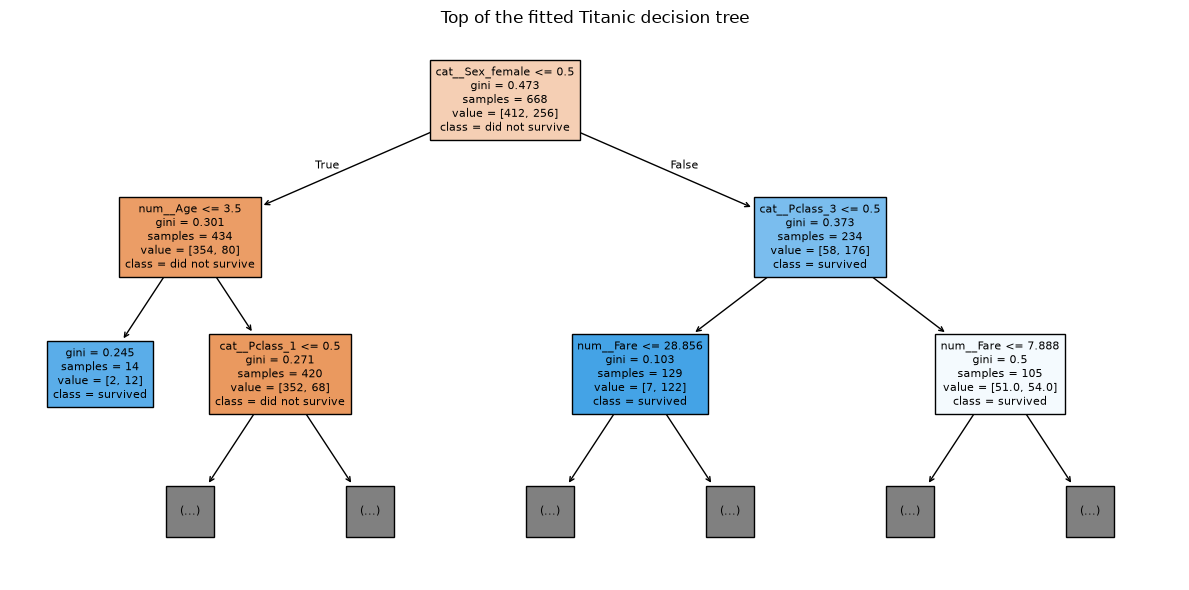

In [17]:
plt.figure(figsize=(12, 6))

plot_tree(
    tree.named_steps["tree"],
    feature_names=feature_names,
    class_names=["did not survive", "survived"],
    max_depth=2,
    filled=True,
    fontsize=8,
)

plt.title("Top of the fitted Titanic decision tree")
plt.tight_layout()
plt.show()

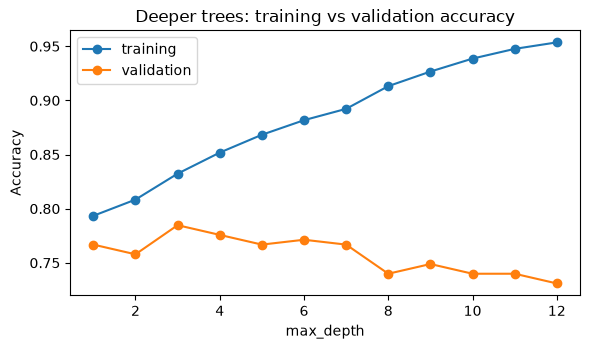

In [18]:
depths = list(range(1, 13))

train_acc = []
valid_acc = []

for depth in depths:
    t = Pipeline([
        ("preprocess", tree_preprocess),
        (
            "tree",
            DecisionTreeClassifier(
                max_depth=depth,
                random_state=42,
            ),
        ),
    ])

    t.fit(Xt_train, yt_train)

    train_acc.append(
        accuracy_score(
            yt_train,
            t.predict(Xt_train),
        )
    )

    valid_acc.append(
        accuracy_score(
            yt_valid,
            t.predict(Xt_valid),
        )
    )

plt.figure(figsize=(6, 3.6))

plt.plot(
    depths,
    train_acc,
    marker="o",
    label="training",
)

plt.plot(
    depths,
    valid_acc,
    marker="o",
    label="validation",
)

plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Deeper trees: training vs validation accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## Part C — Random forest vs gradient boosting

In [20]:
ames = pd.read_csv(DATA / "ames_housing_dataset.csv")

X_a = ames.drop(
    columns=["SalePrice", "Order", "PID"],
    errors="ignore",
)

y_a = np.log1p(ames["SalePrice"])

print("Dataset shape:", ames.shape)
print("Feature shape:", X_a.shape)
print("Target: log(1 + SalePrice)")

Dataset shape: (2930, 82)
Feature shape: (2930, 79)
Target: log(1 + SalePrice)


In [21]:
ames_preprocess = ColumnTransformer([
    (
        "num",
        SimpleImputer(strategy="median"),
        X_a.select_dtypes(include="number").columns,
    ),
    (
        "cat",
        Pipeline([
            (
                "impute",
                SimpleImputer(strategy="most_frequent"),
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
        ]),
        X_a.select_dtypes(exclude="number").columns,
    ),
])

In [22]:
ensembles = {
    "random_forest": RandomForestRegressor(
        n_estimators=150,
        max_features=0.8,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    ),

    "gradient_boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        loss="huber",
        random_state=42,
    ),
}

cv3 = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

In [23]:
cv_rmse = {}

for name, estimator in ensembles.items():
    pipe = Pipeline([
        ("preprocess", ames_preprocess),
        ("model", estimator),
    ])

    neg_mse = cross_val_score(
        pipe,
        X_a,
        y_a,
        cv=cv3,
        scoring="neg_mean_squared_error",
    )

    cv_rmse[name] = np.sqrt(-neg_mse)

    print(
        f"{name:18s} "
        f"CV log-RMSE={cv_rmse[name].mean():.4f} "
        f"+/- {cv_rmse[name].std():.4f}"
    )

random_forest      CV log-RMSE=0.1382 +/- 0.0118
gradient_boosting  CV log-RMSE=0.1273 +/- 0.0141


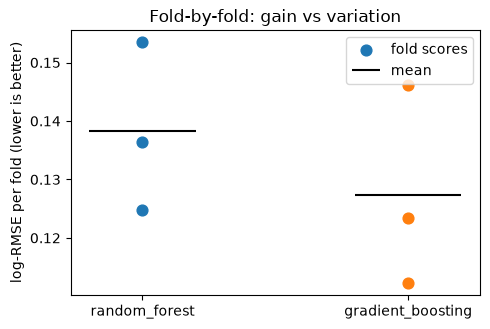

In [24]:
plt.figure(figsize=(5, 3.4))

for i, (name, values) in enumerate(cv_rmse.items()):
    plt.scatter(
        [i] * len(values),
        values,
        s=60,
        label="fold scores" if i == 0 else None,
    )

    plt.hlines(
        values.mean(),
        i - 0.2,
        i + 0.2,
        color="black",
        label="mean" if i == 0 else None,
    )

plt.xticks(
    range(len(cv_rmse)),
    list(cv_rmse),
)

plt.ylabel("log-RMSE per fold (lower is better)")
plt.title("Fold-by-fold: gain vs variation")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
wine = pd.read_csv(DATA / "red_wine_quality_dataset.csv")

X_w = wine.drop(columns="quality")
y_w = wine["quality"]

Xw_train, Xw_valid, yw_train, yw_valid = train_test_split(
    X_w,
    y_w,
    test_size=0.25,
    random_state=42,
)

print("Dataset shape:", wine.shape)
print("Training samples:", len(Xw_train))
print("Validation samples:", len(Xw_valid))

Dataset shape: (1599, 12)
Training samples: 1199
Validation samples: 400


In [26]:
wine_models = {
    "random_forest": RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    ),

    "gradient_boosting": GradientBoostingRegressor(
        random_state=42,
    ),
}

wine_pred = {}

for name, model in wine_models.items():
    model.fit(Xw_train, yw_train)

    wine_pred[name] = model.predict(Xw_valid)

    print(
        f"{name:18s} "
        f"MAE={mean_absolute_error(yw_valid, wine_pred[name]):.3f} "
        f"RMSE={np.sqrt(mean_squared_error(yw_valid, wine_pred[name])):.3f}"
    )

random_forest      MAE=0.432 RMSE=0.565
gradient_boosting  MAE=0.476 RMSE=0.597


In [27]:
importance = permutation_importance(
    wine_models["random_forest"],
    Xw_valid,
    yw_valid,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

ranked = pd.Series(
    importance.importances_mean,
    index=X_w.columns,
).sort_values()

spread = importance.importances_std[
    np.argsort(importance.importances_mean)
]

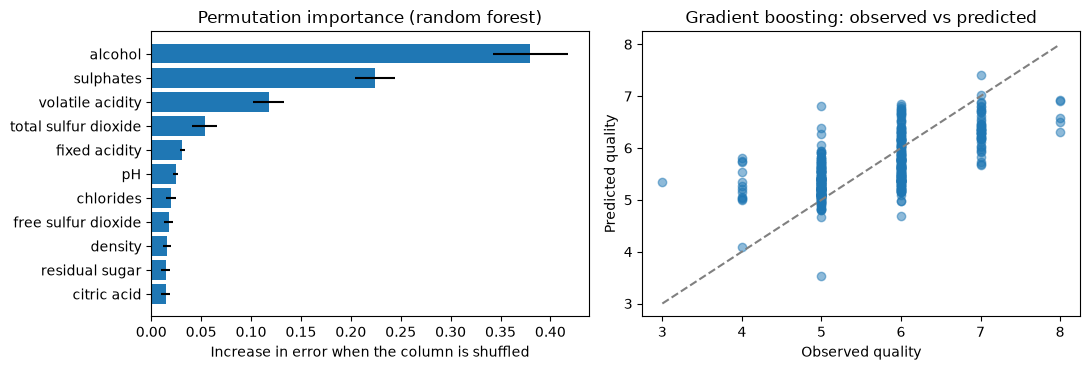

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].barh(
    ranked.index,
    ranked.values,
    xerr=spread,
)

axes[0].set_xlabel(
    "Increase in error when the column is shuffled"
)

axes[0].set_title(
    "Permutation importance (random forest)"
)

axes[1].scatter(
    yw_valid,
    wine_pred["gradient_boosting"],
    alpha=0.5,
)

axes[1].plot(
    [3, 8],
    [3, 8],
    linestyle="--",
    color="grey",
)

axes[1].set_xlabel("Observed quality")
axes[1].set_ylabel("Predicted quality")

axes[1].set_title(
    "Gradient boosting: observed vs predicted"
)

plt.tight_layout()
plt.show()

## Part D — Support vector machines (SVM)

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X_c,
    y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c,
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 426
Test samples: 143


In [30]:
svm_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC()),
])

search = GridSearchCV(
    svm_pipe,
    param_grid={
        "model__kernel": ["linear", "rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.1],
    },
    cv=StratifiedKFold(
        5,
        shuffle=True,
        random_state=42,
    ),
    scoring="roc_auc",
    n_jobs=-1,
)

In [31]:
search.fit(X_train, y_train)

score = search.decision_function(X_test)
pred = search.predict(X_test)

print("Best parameters:", search.best_params_)

print(
    "Cross-validated ROC AUC:",
    round(search.best_score_, 3),
)

print(
    "Test accuracy:",
    round(accuracy_score(y_test, pred), 3),
)

print(
    "Test ROC AUC:",
    round(roc_auc_score(y_test, score), 3),
)

Best parameters: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
Cross-validated ROC AUC: 0.995
Test accuracy: 0.979
Test ROC AUC: 0.997


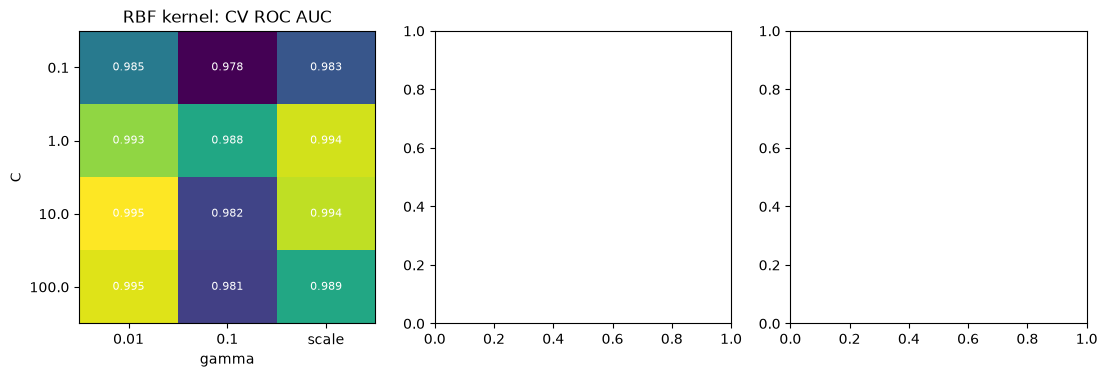

In [32]:
results = pd.DataFrame(search.cv_results_)

rbf = results[
    results["param_model__kernel"] == "rbf"
].copy()

rbf["gamma"] = rbf["param_model__gamma"].astype(str)

grid = rbf.pivot(
    index="param_model__C",
    columns="gamma",
    values="mean_test_score",
)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

im = axes[0].imshow(
    grid.values,
    cmap="viridis",
    aspect="auto",
)

axes[0].set_xticks(
    range(len(grid.columns)),
    grid.columns,
)

axes[0].set_yticks(
    range(len(grid.index)),
    grid.index,
)

axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C")
axes[0].set_title("RBF kernel: CV ROC AUC")

for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        axes[0].text(
            j,
            i,
            f"{grid.values[i, j]:.3f}",
            ha="center",
            va="center",
            color="white",
            fontsize=8,
        )

In [33]:
boundary_estimators = [
    (
        "Linear kernel",
        SVC(kernel="linear", C=1),
    ),
    (
        "RBF kernel (gamma=1)",
        SVC(kernel="rbf", C=1, gamma=1.0),
    ),
]

for ax, (title, estimator) in zip(
    axes[1:],
    boundary_estimators,
):
    small = Pipeline([
        ("scale", StandardScaler()),
        ("model", estimator),
    ])

    small.fit(X_train[two], y_train)

    DecisionBoundaryDisplay.from_estimator(
        small,
        X_test[two],
        ax=ax,
        alpha=0.3,
        response_method="predict",
        cmap="coolwarm",
    )

    ax.scatter(
        X_test[two[0]],
        X_test[two[1]],
        c=y_test,
        cmap="coolwarm",
        s=12,
        edgecolor="k",
        linewidth=0.3,
    )

    ax.set_title(
        f"{title}: "
        f"{accuracy_score(y_test, small.predict(X_test[two])):.2f} "
        "accuracy"
    )

    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [34]:
model_path = MODELS / "breast_cancer_svm.joblib"

joblib.dump(search.best_estimator_, model_path)

loaded = joblib.load(model_path)

same = np.array_equal(
    loaded.predict(X_test),
    pred,
)

print(
    "File size (KB):",
    round(model_path.stat().st_size / 1024, 1),
)

print(
    "Reloaded model reproduces the test predictions:",
    same,
)

File size (KB): 16.5
Reloaded model reproduces the test predictions: True
